# Knowledge Hub · Visualización conceptual

## ¿Por qué se recomienda una guía de monitoreo después de un incidente de pagos?

El recomendador sugirió dos documentos técnicos al consultar el reporte IR01. Para explicar ambos resultados, generamos un grafo a partir de la ontología del proyecto. Los nodos representan documentos, incidentes y lecciones aprendidas. Las flechas muestran las relaciones registradas entre ellos.

La primera prueba compara una referencia directa con una recomendación que surge al recorrer varias relaciones.

In [1]:
%%bash
set -euo pipefail

repo=/content/knowledge-hub-grafo
if [ ! -d "$repo/.git" ]; then
  git clone --quiet --branch fase-2 \
    https://github.com/ierisaac2005-png/softtek-knowledge-hub.git "$repo"
fi

cd "$repo"
git switch --quiet --detach 0c568a5

python -m pip install -q rdflib==7.6.0 graphviz
if ! command -v dot >/dev/null; then
  apt-get update -qq
  apt-get install -y -qq graphviz
fi

printf 'Versión del proyecto: '
git rev-parse --short HEAD

Versión del proyecto: 0c568a5


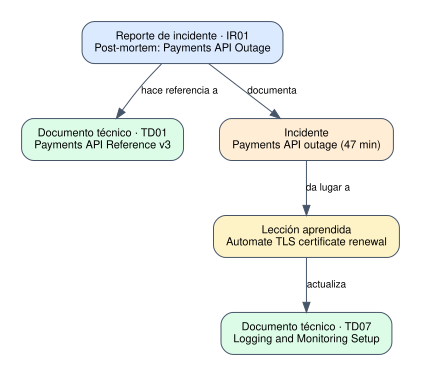

Referencia directa: TD01
Documento vinculado por lección aprendida: TD07


In [2]:
from pathlib import Path
from textwrap import fill

from graphviz import Digraph
from IPython.display import SVG, display
from rdflib import Graph, Literal, Namespace
from rdflib.namespace import RDFS

repo = Path("/content/knowledge-hub-grafo")
g = Graph().parse(repo / "ontology/softtek_ontology.ttl", format="turtle")
ex = Namespace("http://softtek.example/kms#")

source = g.value(predicate=ex.docId, object=Literal("IR01"), any=False)
assert source is not None, "IR01 no se encontró en la ontología."

dot = Digraph(format="svg")
dot.attr(rankdir="TB", bgcolor="white", pad="0.3", nodesep="0.5", ranksep="0.6")
dot.attr("node", shape="box", style="rounded,filled", fontname="Helvetica",
         fontsize="11", margin="0.18,0.12", color="#475569")
dot.attr("edge", fontname="Helvetica", fontsize="10", color="#475569")

def add_node(resource, kind, color):
    title = str(g.value(resource, RDFS.label) or resource.split("#")[-1])
    doc_id = g.value(resource, ex.docId)
    heading = f"{kind} · {doc_id}" if doc_id else kind
    dot.node(str(resource).split("#")[-1],
             label=f"{heading}\n{fill(title, width=32)}", fillcolor=color)

def connect(origin, target, label):
    dot.edge(str(origin).split("#")[-1], str(target).split("#")[-1], label=label)

add_node(source, "Reporte de incidente", "#DBEAFE")
direct_ids = set()
lesson_ids = set()

for target in g.objects(source, ex.references):
    add_node(target, "Documento técnico", "#DCFCE7")
    connect(source, target, "hace referencia a")
    direct_ids.add(str(g.value(target, ex.docId)))

for incident in g.objects(source, ex.documents):
    add_node(incident, "Incidente", "#FFEDD5")
    connect(source, incident, "documenta")

    for lesson in g.objects(incident, ex.resultsIn):
        add_node(lesson, "Lección aprendida", "#FEF3C7")
        connect(incident, lesson, "da lugar a")

        for target in g.objects(lesson, ex.updates):
            add_node(target, "Documento técnico", "#DCFCE7")
            connect(lesson, target, "actualiza")
            lesson_ids.add(str(g.value(target, ex.docId)))

assert "TD01" in direct_ids, "Falta la referencia directa a TD01."
assert "TD07" in lesson_ids, "Falta la ruta de la lección aprendida a TD07."

output = repo / "outputs/grafo_IR01.svg"
output.parent.mkdir(exist_ok=True)
output.write_bytes(dot.pipe(format="svg"))
display(SVG(filename=str(output)))

print("Referencia directa:", ", ".join(sorted(direct_ids)))
print("Documento vinculado por lección aprendida:", ", ".join(sorted(lesson_ids)))

### Interpretación del grafo

El reporte IR01 tiene una referencia directa a TD01, la documentación de la API de pagos. También documenta un incidente que dio lugar a una lección aprendida sobre la renovación de certificados. Esa lección está vinculada con una actualización de TD07, la guía de monitoreo.

En la prueba por similitud textual, TD07 quedó en el lugar 25 de 59. El grafo permite seguir la relación que llevó al recomendador a mostrarlo en segundo lugar.

### Segunda prueba del grafo con el reporte IR03

El recomendador mostró TD04, un esquema de base de datos, y PP07, un procedimiento de gestión de cambios. Vamos a comprobar si la ontología explica ambas recomendaciones y si un mismo documento puede aparecer por más de una ruta.

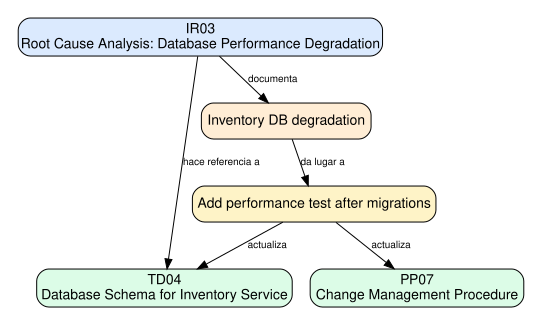

Referencia directa: TD04
Por lección aprendida: PP07, TD04
Por ambas rutas: TD04
Las dos recomendaciones esperadas quedaron verificadas.


In [3]:
from pathlib import Path

from graphviz import Digraph
from IPython.display import SVG, display
from rdflib import Graph, Namespace
from rdflib.namespace import RDFS

proyecto = Path("/content/knowledge-hub-grafo")
datos = Graph().parse(proyecto / "ontology/softtek_ontology.ttl", format="turtle")
kms = Namespace("http://softtek.example/kms#")


def graficar_reporte(documento_id):
    origen = next(
        (nodo for nodo, valor in datos.subject_objects(kms.docId)
         if str(valor) == documento_id),
        None,
    )
    if origen is None:
        raise ValueError(f"No se encontró {documento_id} en la ontología.")

    dibujo = Digraph()
    dibujo.attr(rankdir="TB", bgcolor="white", pad="0.25")
    dibujo.attr("node", shape="box", style="rounded,filled", fontname="Helvetica")
    dibujo.attr("edge", fontname="Helvetica", fontsize="10")

    def agregar_nodo(nodo, color):
        titulo = datos.value(nodo, RDFS.label) or str(nodo).split("#")[-1]
        codigo = datos.value(nodo, kms.docId)
        etiqueta = f"{codigo}\n{titulo}" if codigo else str(titulo)
        dibujo.node(str(nodo).split("#")[-1], etiqueta, fillcolor=color)

    def enlazar(desde, hasta, relacion):
        dibujo.edge(str(desde).split("#")[-1], str(hasta).split("#")[-1],
                    label=relacion)

    directos = set()
    por_leccion = set()
    agregar_nodo(origen, "#dbeafe")

    for destino in datos.objects(origen, kms.references):
        agregar_nodo(destino, "#dcfce7")
        enlazar(origen, destino, "hace referencia a")
        directos.add(str(datos.value(destino, kms.docId)))

    for incidente in datos.objects(origen, kms.documents):
        agregar_nodo(incidente, "#ffedd5")
        enlazar(origen, incidente, "documenta")
        for leccion in datos.objects(incidente, kms.resultsIn):
            agregar_nodo(leccion, "#fef3c7")
            enlazar(incidente, leccion, "da lugar a")
            for destino in datos.objects(leccion, kms.updates):
                agregar_nodo(destino, "#dcfce7")
                enlazar(leccion, destino, "actualiza")
                por_leccion.add(str(datos.value(destino, kms.docId)))

    archivo = proyecto / "outputs" / f"grafo_{documento_id}.svg"
    archivo.parent.mkdir(exist_ok=True)
    archivo.write_bytes(dibujo.pipe(format="svg"))
    display(SVG(filename=str(archivo)))
    return directos, por_leccion


directos, por_leccion = graficar_reporte("IR03")

print("Referencia directa:", ", ".join(sorted(directos)) or "Ninguna")
print("Por lección aprendida:", ", ".join(sorted(por_leccion)) or "Ninguno")
print("Por ambas rutas:", ", ".join(sorted(directos & por_leccion)) or "Ninguno")

assert "TD04" in directos, "Falta la referencia directa a TD04."
assert "PP07" in por_leccion, "Falta el vínculo de la lección con PP07."
print("Las dos recomendaciones esperadas quedaron verificadas.")

### Cobertura de las recomendaciones explicadas por la ontología

En IR03 comprobamos que un documento puede estar relacionado por dos rutas distintas. Ahora medimos cuántos documentos del corpus permiten llegar a otro documento mediante una referencia directa o una lección aprendida. Cada documento de origen cuenta una sola vez, aunque tenga varios vínculos.

In [4]:
from collections import Counter

# El corpus evaluado en esta versión del proyecto contiene 60 documentos.
total_corpus = 60
conteo = Counter()

for origen in set(datos.subjects(kms.docId, None)):
    directos = set(datos.objects(origen, kms.references))
    por_leccion = {
        destino
        for incidente in datos.objects(origen, kms.documents)
        for leccion in datos.objects(incidente, kms.resultsIn)
        for destino in datos.objects(leccion, kms.updates)
    }

    # Contamos vínculos hacia otro documento identificado en la ontología.
    def tiene_otro_documento(destinos):
        return any(
            destino != origen and datos.value(destino, kms.docId) is not None
            for destino in destinos
        )

    directa = tiene_otro_documento(directos)
    leccion = tiene_otro_documento(por_leccion)
    conteo["directa"] += directa
    conteo["leccion"] += leccion
    conteo["ambas"] += directa and leccion
    conteo["con_ruta"] += directa or leccion

cubiertos = conteo["con_ruta"]
print(f"Con referencia directa:             {conteo['directa']}")
print(f"Con ruta por lección aprendida:     {conteo['leccion']}")
print(f"Con ambos tipos de ruta:            {conteo['ambas']}")
print(f"Cobertura sobre el corpus:          {cubiertos}/{total_corpus} ({cubiertos/total_corpus:.1%})")
print(f"Sin estas rutas de salida:          {total_corpus - cubiertos}/{total_corpus}")

Con referencia directa:             6
Con ruta por lección aprendida:     2
Con ambos tipos de ruta:            2
Cobertura sobre el corpus:          6/60 (10.0%)
Sin estas rutas de salida:          54/60


La ontología permite explicar recomendaciones para 6 de los 60 documentos del corpus (10%). En dos de esos seis casos, las lecciones aprendidas aportan una segunda ruta. Para los otros 54 documentos, el recomendador utiliza similitud textual. El 10% mide la cobertura de los vínculos explícitos. La relevancia de las recomendaciones se evalúa por separado.

In [5]:
import sys
from pathlib import Path

proyecto = Path("/content/knowledge-hub-grafo")
sys.path.insert(0, str(proyecto / "src"))

from kms_utils import load_documents

documentos = load_documents().set_index("id")
orden_observado = ["TD12", "IR03", "IR01", "IR05", "IR12"]

for posicion, doc_id in enumerate(["IR07", *orden_observado]):
    doc = documentos.loc[doc_id]
    etiqueta = "Documento consultado" if posicion == 0 else f"Recomendación {posicion}"
    print(f"{etiqueta} · {doc_id} · {doc['title']}")
    print(doc["text"], end="\n\n")

Documento consultado · IR07 · Post-mortem: Message Queue Backlog
Order events accumulated in the queue and were processed with a delay of three hours. The root cause was a consumer that crashed due to an unhandled malformed message. A fix was deployed and monitoring of queue depth was added to the alerts.

Recomendación 1 · TD12 · Message Queue Integration Guide
Producers publish order events to the RabbitMQ exchange using a routing key per event type. Consumers must acknowledge messages after processing and failed messages are sent to a dead letter queue. Payloads are serialized with Avro schemas registered in the schema registry.

Recomendación 2 · IR03 · Root Cause Analysis: Database Performance Degradation
Response times of the inventory service increased tenfold during the peak hour. The root cause analysis found a missing index after a schema migration. The index was restored and a performance test was added to the release checklist.

Recomendación 3 · IR01 · Post-mortem: Payment

### Evaluación manual de las recomendaciones para IR07

Se consideró relevante un documento si aportaba información concreta para entender, detectar o prevenir la acumulación de mensajes descrita en IR07.

| Posición | Documento | ¿Es relevante? | Motivo |
|---|---|---|---|
| 1 | TD12 · Integración de colas de mensajes | Sí | Explica cómo se confirman los mensajes procesados y adónde se envían los fallidos. Esto ayuda a investigar qué ocurre cuando el consumidor recibe un mensaje malformado. |
| 2 | IR03 · Rendimiento de la base de datos | No | El retraso se atribuye a un índice faltante y se resuelve restaurando ese índice. |
| 3 | IR01 · Caída de la API de pagos | No | La medida preventiva vigila el vencimiento de un certificado TLS. |
| 4 | IR05 · Despliegue fallido | No | El reporte describe cómo revertir un cambio de configuración que afectó al servicio de pagos. |
| 5 | IR12 · Disco lleno en el servidor de registros | No | La revisión de alertas es una idea transferible, pero el indicador que analiza el documento es el espacio en disco. |

**Resultado para IR07:** P@5 = 1/5 = 20%. La única recomendación relevante quedó en primer lugar. Las cuatro restantes describen incidentes con causas distintas.

In [6]:
# Rankings registrados en las dos pruebas anteriores con IR01
vinculados_ir01 = {"TD01", "TD07"}
rankings_ir01 = {
    "Solo similitud textual": ["IR10", "TD01", "IR07", "IR05", "IR12"],
    "Ontología + similitud":  ["TD01", "TD07", "IR10", "IR07", "IR05"],
}

for metodo, ranking in rankings_ir01.items():
    recuperados = [doc for doc in ranking[:5] if doc in vinculados_ir01]
    recall = len(recuperados) / len(vinculados_ir01)
    print(f"{metodo}: {', '.join(recuperados)}")
    print(f"  Recall@5 sobre vínculos conocidos: "
          f"{len(recuperados)}/{len(vinculados_ir01)} = {recall:.0%}\n")

Solo similitud textual: TD01
  Recall@5 sobre vínculos conocidos: 1/2 = 50%

Ontología + similitud: TD01, TD07
  Recall@5 sobre vínculos conocidos: 2/2 = 100%



### Conclusión del grafo y las recomendaciones

| Prueba | Resultado | Interpretación |
|---|---|---|
| IR01 · Recuperación de vínculos conocidos | Recall@5 pasó de 1/2 a 2/2 | La lección aprendida llevó la guía de monitoreo TD07 del puesto 25 al 2. |
| IR03 · Explicación visual | Dos rutas hacia TD04 y una hacia PP07 | El grafo muestra por qué se recomienda cada documento y permite ver cuándo dos rutas llegan al mismo destino. |
| IR07 · Relevancia de las sugerencias por texto | P@5 = 1/5 | La guía de integración de colas quedó primera. Las otras cuatro sugerencias trataban incidentes con causas distintas. |
| Corpus · Cobertura de vínculos explícitos | 6/60 documentos (10%) | Seis documentos permiten explicar al menos una recomendación mediante una ruta en la ontología. |

La principal oportunidad de mejora es ampliar los vínculos documentados y evaluar más casos de relevancia. Esto permitiría medir si la mejora observada en IR01 también se presenta en otros documentos.